# [Project title] ??

**Team members:** Nina Breen, Marin Marcillac, Claire McGinn, Roney Nguyen
**Repository:** https://github.com/9-uh/DS3001_Project_Group4

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

## Load data

In [2]:
listing_df = pd.read_csv('data/listing_data.csv')
calendar_df = pd.read_csv('data/past_calendar_rates.csv')


## Prepare data

In [3]:
calendar_df["date"] = pd.to_datetime(calendar_df["date"], errors="coerce")

# Track missingness for key fields
for col in ["bedrooms", "guests"]:
    if col in listing_df.columns:
        listing_df[f"{col}_was_missing"] = listing_df[col].isna().astype(int)

# if the bedroom was not listed but the description or listing name contains "studio", set bedroom to 1
studio_mask = (
    listing_df["bedrooms"].isna()
    & (
        listing_df["listing_name"].fillna("").str.contains("studio", case=False, regex=False)
        | listing_df["description"].fillna("").str.contains("studio", case=False, regex=False)
    )
)
listing_df.loc[studio_mask, "bedrooms"] = 1.0
# filling other bedrooms with the median
bedroom_median_int = int(round(listing_df["bedrooms"].median()))
listing_df["bedrooms"] = listing_df["bedrooms"].fillna(bedroom_median_int).astype(int)

bool_cols = [
    "superhost", "registration", "professional_management",
    "instant_book", "guest_favorite", "exact_location", "single_fee_structure"
]
for col in bool_cols:
    if col in listing_df.columns:
        mapped = listing_df[col].map({True: 1, False: 0, "True": 1, "False": 0})
        listing_df[col] = mapped.fillna(0).astype(int)

# 3. Median-impute numeric listing features
num_cols = [
    "guests", "beds", "baths", "cleaning_fee", "min_nights",
    "num_reviews", "rating_overall", "rating_accuracy", "rating_checkin",
    "rating_cleanliness", "rating_communication", "rating_location", "rating_value",
    "ttm_avg_rate", "ttm_occupancy", "l90d_avg_rate", "l90d_occupancy"
]
for col in num_cols:
    if col in listing_df.columns:
        listing_df[col] = pd.to_numeric(listing_df[col], errors="coerce")
        listing_df[col] = listing_df[col].fillna(listing_df[col].median())

# 4. Drop IDs, text/URLs, sparse cols, and extra ttm/l90d duplicates
drop_listing = [
    "host_id", "listing_name", "description", "cover_photo_url", "photo_urls",
    "host_name", "cohost_ids", "cohost_names", "amenities", "checkin_time", "checkout_time",
    "extra_guest_fee", "currency", "ttm_total_days", "l90d_total_days",
    "ttm_revenue", "ttm_revenue_native", "ttm_avg_rate_native", "ttm_revpar",
    "ttm_revpar_native", "ttm_adjusted_revpar", "ttm_adjusted_revpar_native",
    "ttm_avg_min_nights", "ttm_avg_length_of_stay", "ttm_reserved_days",
    "ttm_blocked_days", "ttm_available_days", "ttm_adjusted_occupancy",
    "l90d_revenue", "l90d_revenue_native", "l90d_avg_rate_native", "l90d_revpar",
    "l90d_revpar_native", "l90d_adjusted_revpar", "l90d_adjusted_revpar_native",
    "l90d_avg_min_nights", "l90d_avg_length_of_stay", "l90d_reserved_days",
    "l90d_blocked_days", "l90d_available_days", "l90d_adjusted_occupancy"
]
listing_clean = listing_df.drop(columns=[c for c in drop_listing if c in listing_df.columns]).copy()

# Group rare categories (< 5 listings) in listing_type before one-hot encoding
if "listing_type" in listing_clean.columns:
    lt = listing_clean["listing_type"].fillna("Missing").astype(str)
    vc = lt.value_counts()
    rare_types = vc[vc < 5].index
    listing_clean["listing_type"] = lt.replace(rare_types, "Other_listing_type")

cat_cols = [c for c in ["room_type", "listing_type", "cancellation_policy"] if c in listing_clean.columns]
listing_clean[cat_cols] = listing_clean[cat_cols].fillna("Missing").astype(str)
listing_clean = pd.get_dummies(listing_clean, columns=cat_cols, drop_first=False, dtype=int)

# Clean calendar columns and merge
if "min_nights_avg" in calendar_df.columns:
    calendar_df["min_nights_avg"] = calendar_df["min_nights_avg"].fillna(calendar_df["min_nights_avg"].median())

drop_cal = [
    "booked_rate_avg", "booking_lead_time_avg", "length_of_stay_avg",
    "native_booked_rate_avg", "native_rate_avg", "native_revenue"
]
calendar_clean = calendar_df.drop(columns=[c for c in drop_cal if c in calendar_df.columns]).copy()

df_merged = (
    calendar_clean.merge(listing_clean, on="listing_id", how="inner")
    .dropna(subset=["listing_id", "date", "rate_avg"])
    .sort_values(["listing_id", "date"])
    .reset_index(drop=True)
)

unique_dates = sorted(df_merged["date"].unique())
df_1m = df_merged[df_merged["date"].isin(unique_dates[-1:])].copy().reset_index(drop=True)
df_3m = df_merged[df_merged["date"].isin(unique_dates[-3:])].copy().reset_index(drop=True)
df_6m = df_merged[df_merged["date"].isin(unique_dates[-6:])].copy().reset_index(drop=True)

print("Lean df_merged shape:", df_merged.shape)

Lean df_merged shape: (1174, 53)


In [51]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 1174 entries, 0 to 1173
Data columns (total 53 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   listing_id                                1174 non-null   int64         
 1   date                                      1174 non-null   datetime64[us]
 2   vacant_days                               1174 non-null   int64         
 3   reserved_days                             1174 non-null   int64         
 4   occupancy                                 1174 non-null   float64       
 5   revenue                                   1174 non-null   float64       
 6   rate_avg                                  1174 non-null   float64       
 7   min_nights_avg                            1174 non-null   float64       
 8   photos_count                              1174 non-null   int64         
 9   superhost                                

## Explore data

=== Dataset Shapes ===
df_merged: 1174 rows x 53 cols | unique listings: 100
df_6m: 586 rows x 53 cols | unique listings: 100
df_3m: 294 rows x 53 cols | unique listings: 98
df_1m: 98 rows x 53 cols | unique listings: 98

=== Target (rate_avg) Summary Across DataFrames ===


,dataset,n_rows,n_listings,mean,median,std,min,max
0,df_merged,1174,100,172.63,145.85,116.45,45.4,912.0
1,df_6m,586,100,176.25,147.70,116.02,48.5,912.0
2,df_3m,294,98,182.92,161.40,118.98,55.2,910.5
3,df_1m,98,98,182.48,164.30,118.62,55.2,910.0



=== Monthly rate_avg Trend ===


C:\Users\roney\AppData\Local\Temp\ipykernel_9168\3598978227.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.round(2))


,date,count,mean,median,std
0,2025-08-01,98,169.36,150.80,115.57
1,2025-09-01,98,171.00,141.70,118.88
2,2025-10-01,98,172.20,144.65,121.05
3,2025-11-01,98,171.10,142.25,119.39
4,2025-12-01,98,169.04,140.05,116.79
5,2026-01-01,98,161.41,137.50,112.00
6,2026-02-01,98,161.95,134.95,112.47
7,2026-03-01,96,171.33,143.65,112.45
8,2026-04-01,98,175.33,146.90,114.09
9,2026-05-01,98,181.02,152.90,119.37



=== rate_avg by Entire Home Flag ===


,count,mean,median,std
room_type_entire_home,,,,
0,560,151.51,126.3,95.32
1,614,191.88,155.6,129.95


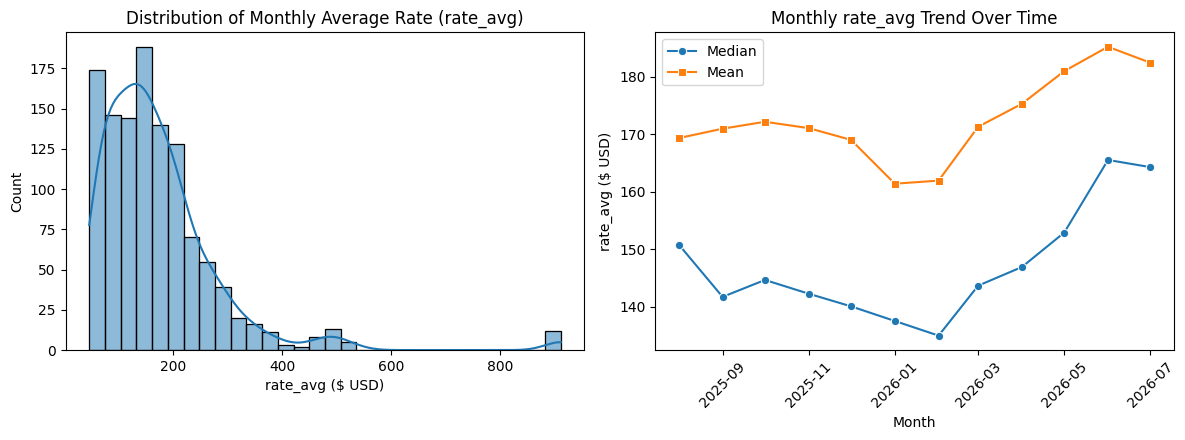

In [4]:
print("=== Dataset Shapes ===")
for name, d in [("df_merged", df_merged), ("df_6m", df_6m), ("df_3m", df_3m), ("df_1m", df_1m)]:
    print(f"{name}: {d.shape[0]} rows x {d.shape[1]} cols | unique listings: {d['listing_id'].nunique()}")

print("\n=== Target (rate_avg) Summary Across DataFrames ===")
summary_rows = []
for name, d in [("df_merged", df_merged), ("df_6m", df_6m), ("df_3m", df_3m), ("df_1m", df_1m)]:
    s = d["rate_avg"]
    summary_rows.append({
        "dataset": name,
        "n_rows": len(d),
        "n_listings": d["listing_id"].nunique(),
        "mean": round(s.mean(), 2),
        "median": round(s.median(), 2),
        "std": round(s.std(), 2),
        "min": round(s.min(), 2),
        "max": round(s.max(), 2),
    })
display(pd.DataFrame(summary_rows))

print("\n=== Monthly rate_avg Trend ===")
monthly_summary = (
    df_merged.groupby("date")["rate_avg"]
    .agg(count="count", mean="mean", median="median", std="std")
    .reset_index()
)
display(monthly_summary.round(2))

print("\n=== rate_avg by Entire Home Flag ===")
if "room_type_entire_home" in df_merged.columns:
    display(
        df_merged.groupby("room_type_entire_home")["rate_avg"]
        .agg(count="count", mean="mean", median="median", std="std")
        .round(2)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df_merged["rate_avg"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Monthly Average Rate (rate_avg)")
axes[0].set_xlabel("rate_avg ($ USD)")
axes[0].set_ylabel("Count")

sns.lineplot(data=monthly_summary, x="date", y="median", marker="o", label="Median", ax=axes[1])
sns.lineplot(data=monthly_summary, x="date", y="mean", marker="s", label="Mean", ax=axes[1])
axes[1].set_title("Monthly rate_avg Trend Over Time")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("rate_avg ($ USD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

=== Candidate Feature Summary (df_merged) ===


,count,mean,std,min,50%,max
bedrooms,1174.0,1.19,0.55,1.0,1.00,5.0
guests,1174.0,2.36,0.88,1.0,2.00,5.0
beds,1174.0,1.59,0.97,1.0,1.00,7.0
baths,1174.0,0.63,0.59,0.0,1.00,3.0
min_nights,1174.0,21.97,12.31,1.0,30.00,35.0
min_nights_avg,1174.0,21.90,12.60,1.0,30.00,60.0
cleaning_fee,1174.0,2070.09,2094.26,0.0,1595.50,7334.0
num_reviews,1174.0,203.37,160.85,2.0,169.00,690.0
rating_overall,1174.0,4.80,0.13,4.4,4.82,5.0
occupancy,1174.0,0.30,0.37,0.0,0.05,1.0


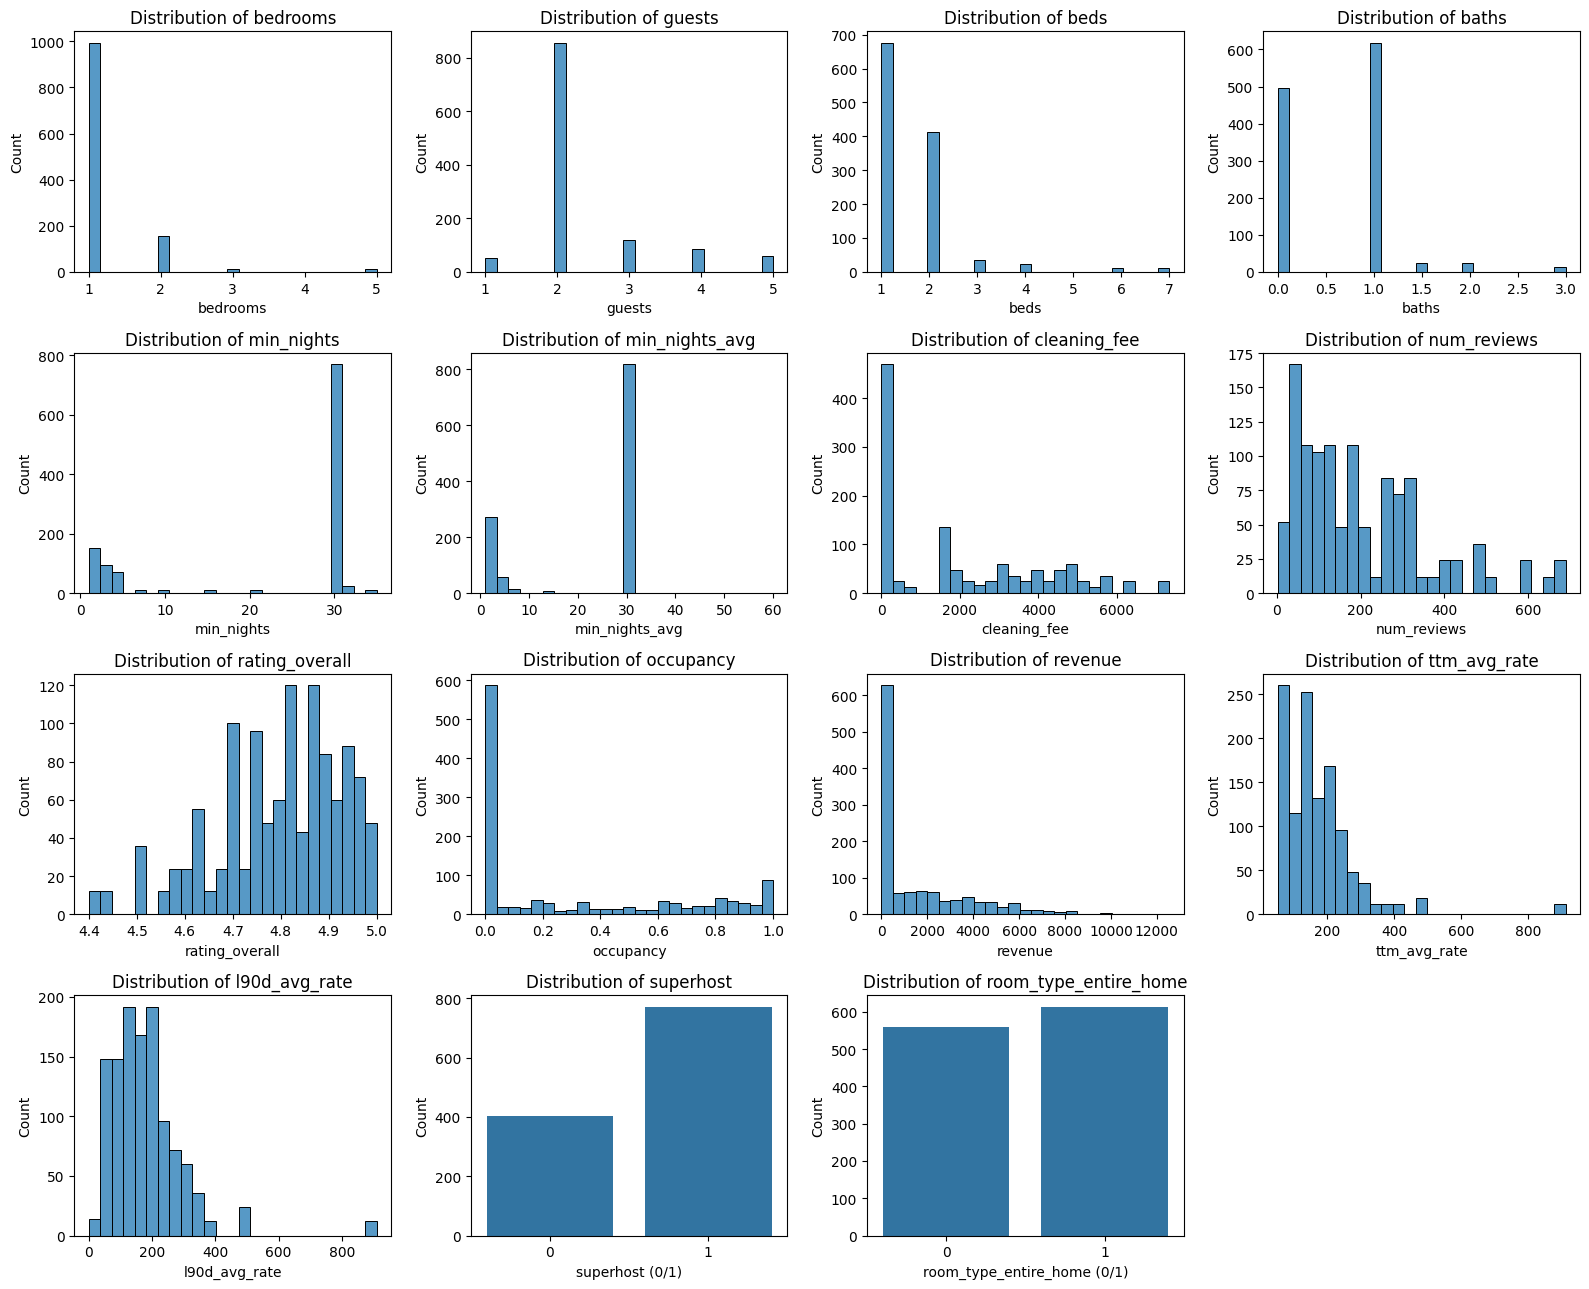

In [5]:
feature_candidates = [
    "bedrooms", "guests", "beds", "baths", "min_nights", "min_nights_avg",
    "cleaning_fee", "num_reviews", "rating_overall", "occupancy", "revenue",
    "ttm_avg_rate", "l90d_avg_rate", "superhost", "room_type_entire_home"
]
present_features = [c for c in feature_candidates if c in df_merged.columns]

print("=== Candidate Feature Summary (df_merged) ===")
display(df_merged[present_features].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

n_cols = 4
n_rows = int(np.ceil(len(present_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.25 * n_rows))
axes_flat = axes.flatten()

for idx, col in enumerate(present_features):
    ax = axes_flat[idx]
    is_binary = set(df_merged[col].dropna().unique()).issubset({0, 1})
    if is_binary:
        sns.countplot(data=df_merged, x=col, ax=ax)
        ax.set_xlabel(f"{col} (0/1)")
    else:
        sns.histplot(df_merged[col], bins=25, kde=False, ax=ax)
        ax.set_xlabel(col)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Count")

for idx in range(len(present_features), len(axes_flat)):
    axes_flat[idx].axis("off")

plt.tight_layout()
plt.show()

## Build models

In [6]:

from sklearn.linear_model import LinearRegression, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor


In [7]:
# Make a copy so we don't change the original cleaned data
model_df = df_merged.copy()

# Our calendar data is monthly, so turn each date into a month
model_df["month"] = pd.to_datetime(model_df["date"]).dt.to_period("M")

# Each listing should only have one row per month.
# Otherwise, we would not know which monthly rate to use.
duplicates = model_df.duplicated(
    subset=["listing_id", "month"]
).sum()

print("Duplicate listing-month rows:", duplicates)

if duplicates > 0:
    raise ValueError("Check the duplicate listing-month rows.")

Duplicate listing-month rows: 0


In [8]:
# We want to predict a month's rate using earlier rates
# for the same listing.

for lag in range(1, 7):

    # Keep the listing ID, month, and rate
    past_rates = model_df[
        ["listing_id", "month", "rate_avg"]
    ].copy()

    # Move the month forward so an earlier rate matches
    # the month we are trying to predict
    past_rates["month"] = past_rates["month"] + lag

    # Give each past rate a name based on how old it is
    past_rates = past_rates.rename(
        columns={"rate_avg": f"rate_{lag}_month_ago"}
    )

    # Match the previous rate to the correct listing and month
    model_df = model_df.merge(
        past_rates,
        on=["listing_id", "month"],
        how="left",
        validate="one_to_one"
    )
# Check the new columns
display(
    model_df[
        [
            "listing_id",
            "month",
            "rate_avg",
            "rate_1_month_ago",
            "rate_2_month_ago",
            "rate_3_month_ago"
        ]
    ].head(10)
)

,listing_id,month,rate_avg,rate_1_month_ago,rate_2_month_ago,rate_3_month_ago
0,2539,2025-08,91.2,NaN,NaN,NaN
1,2539,2025-09,89.5,91.2,NaN,NaN
2,2539,2025-10,95.5,89.5,91.2,NaN
3,2539,2025-11,89.6,95.5,89.5,91.2
4,2539,2025-12,91.9,89.6,95.5,89.5
5,2539,2026-01,82.6,91.9,89.6,95.5
6,2539,2026-02,85.0,82.6,91.9,89.6
7,2539,2026-03,76.3,85.0,82.6,91.9
8,2539,2026-04,68.2,76.3,85.0,82.6
9,2539,2026-05,66.9,68.2,76.3,85.0


In [9]:
# The 1-month window is the rate from the previous month
model_df["past_1m_avg"] = model_df["rate_1_month_ago"]

# The 3-month window is the average of the previous 3 months
model_df["past_3m_avg"] = model_df[
    [
        "rate_1_month_ago",
        "rate_2_month_ago",
        "rate_3_month_ago"
    ]
].mean(axis=1, skipna=False)

# The 6-month window is the average of the previous 6 months
model_df["past_6m_avg"] = model_df[
    [
        "rate_1_month_ago",
        "rate_2_month_ago",
        "rate_3_month_ago",
        "rate_4_month_ago",
        "rate_5_month_ago",
        "rate_6_month_ago"
    ]
].mean(axis=1, skipna=False)


# Check the historical averages
display(
    model_df[
        [
            "listing_id",
            "month",
            "rate_avg",
            "past_1m_avg",
            "past_3m_avg",
            "past_6m_avg"
        ]
    ].head(10)
)

,listing_id,month,rate_avg,past_1m_avg,past_3m_avg,past_6m_avg
0,2539,2025-08,91.2,NaN,NaN,NaN
1,2539,2025-09,89.5,91.2,NaN,NaN
2,2539,2025-10,95.5,89.5,NaN,NaN
3,2539,2025-11,89.6,95.5,92.066667,NaN
4,2539,2025-12,91.9,89.6,91.533333,NaN
5,2539,2026-01,82.6,91.9,92.333333,NaN
6,2539,2026-02,85.0,82.6,88.033333,90.050000
7,2539,2026-03,76.3,85.0,86.500000,89.016667
8,2539,2026-04,68.2,76.3,81.300000,86.816667
9,2539,2026-05,66.9,68.2,76.500000,82.266667


In [10]:
# These property features are used in every model
property_features = [
    "bedrooms",
    "guests",
    "beds",
    "baths",
    "latitude",
    "longitude",
#added other features
    "min_nights",
    "cleaning_fee",
    "num_reviews",
    "rating_overall",
    "room_type_entire_home"
]

# Keep rows with all the information needed for our models
required_columns = (
    ["listing_id", "month", "rate_avg"]
    + property_features
    + ["past_1m_avg", "past_3m_avg", "past_6m_avg"]
)

model_df = model_df.dropna(subset=required_columns).copy()

# All three windows now use the same rows.
# This makes the comparison between windows fairer.
print("Rows available for modeling:", len(model_df))
print("Unique listings:", model_df["listing_id"].nunique())
print("Months available:", sorted(model_df["month"].unique()))

# In our results, we have 578 rows and 98 unique listings.
# These rows have the information needed for all 3 windows.

Rows available for modeling: 578
Unique listings: 98
Months available: [Period('2026-02', 'M'), Period('2026-03', 'M'), Period('2026-04', 'M'), Period('2026-05', 'M'), Period('2026-06', 'M'), Period('2026-07', 'M')]


In [11]:
# Sort the months from earliest to latest
months = sorted(model_df["month"].unique())

# Use the most recent month as the test month
test_month = months[-1]

# Use the earlier months for training and validation
train_months = months[:-1]

train = model_df[
    model_df["month"].isin(train_months)
].copy()

test = model_df[
    model_df["month"] == test_month
].copy()

print("Training months:", train_months)
print("Test month:", test_month)
print("Training rows:", len(train))
print("Test rows:", len(test))

# In our results, February through June are used for training
# and July is used as the test month.
# July has 96 listing-month observations.

Training months: [Period('2026-02', 'M'), Period('2026-03', 'M'), Period('2026-04', 'M'), Period('2026-05', 'M'), Period('2026-06', 'M')]
Test month: 2026-07
Training rows: 482
Test rows: 96


In [12]:
# Cross-validation helps us compare models using the training data.
# We use time-based folds so validation happens after training.

time_cv = TimeSeriesSplit(
    n_splits=min(3, len(train_months) - 1)
)

folds = []

for train_month_idx, val_month_idx in time_cv.split(train_months):

    # Find the months for this training and validation split
    fold_train_months = [
        train_months[i] for i in train_month_idx
    ]

    fold_val_months = [
        train_months[i] for i in val_month_idx
    ]

    # Find the row positions for those months
    fold_train_idx = np.flatnonzero(
        train["month"].isin(fold_train_months)
    )

    fold_val_idx = np.flatnonzero(
        train["month"].isin(fold_val_months)
    )

    folds.append((fold_train_idx, fold_val_idx))

    print(
        "Training:", fold_train_months,
        "| Validation:", fold_val_months
    )

# Each fold trains on earlier months and validates on a later month.
# This helps us choose a model before looking at the July test error.

Training: [Period('2026-02', 'M'), Period('2026-03', 'M')] | Validation: [Period('2026-04', 'M')]
Training: [Period('2026-02', 'M'), Period('2026-03', 'M'), Period('2026-04', 'M')] | Validation: [Period('2026-05', 'M')]
Training: [Period('2026-02', 'M'), Period('2026-03', 'M'), Period('2026-04', 'M'), Period('2026-05', 'M')] | Validation: [Period('2026-06', 'M')]


In [13]:
# Compare three amounts of historical rate data
windows = {
    "1 month": "past_1m_avg",
    "3 months": "past_3m_avg",
    "6 months": "past_6m_avg"
}

# LASSO's alpha controls how strong the penalty is.
# Larger alpha values shrink the coefficients more.
alpha_values = [0.01, 0.1, 0.3, 1, 3, 10, 30]

# kNN hyperparameters
k_values = [1, 3, 5, 7, 10, 15, 20]

# Random Forest hyperparameters
n_estimators_values = [50, 100, 200]
max_depth_values = [3, 5, 10, None]


# Save the trained models so we can evaluate them later
trained_models = {}

In [14]:
# Train both models for each historical window
for window_name, history_feature in windows.items():

    # Every model gets the same property features.
    # The historical rate window is what changes.
    features = [history_feature] + property_features

    X_train = train[features]
    y_train = train["rate_avg"]


    # Ordinary linear regression
   

    # Linear regression uses the features to predict the rate.
    # It chooses coefficients to reduce squared training errors.
    linear_model = make_pipeline(
        StandardScaler(),
        LinearRegression(),
    )

    # Use the same time-based folds for both models
    linear_search = GridSearchCV(
        linear_model,
        param_grid={},
        cv=folds,
        scoring="neg_root_mean_squared_error"
    )

    linear_search.fit(X_train, y_train)


    # LASSO regression
 

    # LASSO is also a linear model, but it adds a penalty
    # that shrinks coefficients and can set some to zero.
    lasso_model = make_pipeline(
        StandardScaler(),
        Lasso(max_iter=20000)
    )

    # Test different alpha values, like in the class slides.
    # Scaling happens within each training fold.
    lasso_search = GridSearchCV(
        lasso_model,
        param_grid={"lasso__alpha": alpha_values},
        cv=folds,
        scoring="neg_root_mean_squared_error"
    )

    lasso_search.fit(X_train, y_train)


    #   K Nearest Number

    knn_model = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor()
    )   

    knn_search = GridSearchCV(
        knn_model,
        param_grid={
            "kneighborsregressor__n_neighbors": k_values
        },
        cv=folds,
        scoring="neg_root_mean_squared_error"
    )
    
    knn_search.fit(X_train, y_train)

    #   Random Forest Regression

    rf_model = RandomForestRegressor(
        random_state=42
    )

    rf_search = GridSearchCV(
        rf_model,
        param_grid={
            "n_estimators": n_estimators_values,
            "max_depth": max_depth_values
        },
        cv=folds,
        scoring="neg_root_mean_squared_error"
    )

    rf_search.fit(X_train, y_train)

    # Save all trained searches and the features they used

    trained_models[("Linear regression", window_name)] = {
        "search": linear_search,
        "features": features
    }

    trained_models[("LASSO", window_name)] = {
        "search": lasso_search,
        "features": features
    }

    trained_models[("kNN", window_name)] = {
        "search": knn_search,
        "features": features
    }

    trained_models[("Random Forest", window_name)] = {
        "search": rf_search,
        "features": features
    }


    print(f"Finished training models for {window_name}")

# We now have 12 models:
# 4 model types × 3 historical windows.

Finished training models for 1 month
Finished training models for 3 months
Finished training models for 6 months


## Evaluate models

In [15]:
#Including a baseline simple prediction for comparison
baseline_results = []

for window_name, history_feature in windows.items():

    y_test = test["rate_avg"]
    y_pred = test[history_feature]

    baseline_results.append({
        "Model": "Historical Average Baseline",
        "History window": window_name,
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Test R²": r2_score(y_test, y_pred)
    })

display(pd.DataFrame(baseline_results).round(2))

,Model,History window,Test MAE,Test RMSE,Test R²
0,Historical Average Baseline,1 month,9.22,21.51,0.97
1,Historical Average Baseline,3 months,10.11,17.12,0.98
2,Historical Average Baseline,6 months,15.69,25.08,0.95


In [20]:
# Store the results for each model
results = []

# Evaluate every model on the same test month
for (model_name, window_name), info in trained_models.items():

    # Get the trained model and its features
    model = info["search"]
    features = info["features"]

    # Make predictions for July
    y_test = test["rate_avg"]
    predictions = model.predict(test[features])

    # MAE is the average absolute prediction error
    mae = mean_absolute_error(y_test, predictions)

    # RMSE gives larger errors more weight
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    # R² measures how well predictions explain variation
    # in the test rates
    r2 = r2_score(y_test, predictions)

    # Only LASSO has an alpha value
    if model_name == "LASSO":
        alpha = model.best_params_["lasso__alpha"]
    else:
        alpha = np.nan

    # Save each model's results
    results.append({
        "Model": model_name,
        "History window": window_name,
        "CV RMSE": -model.best_score_,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R²": r2,
        "Best alpha": alpha,
    })

# Make a table that we can use in the final results
results_df = pd.DataFrame(results)

In [21]:
# Sort by cross-validation RMSE to choose the model
# before judging it on the July test set
final_results = results_df.sort_values(
    "CV RMSE"
).reset_index(drop=True)

print("Final Model Comparison")
display(final_results.round(2))

# The 1-month LASSO model had the lowest CV RMSE of $15.90,
# closely followed by linear regression at $15.93.
# LASSO's regularization provided only a small advantage
# over regular linear regression.

# All four models performed best during cross-validation
# when using 1 month of historical pricing data.

# The 3-month LASSO model had the lowest July test RMSE
# among the machine learning models at $18.58.

# Random Forest and kNN generally performed worse than
# LASSO and linear regression, suggesting that more complex
# models did not necessarily improve prediction accuracy.

# kNN selected 1 neighbor across all three historical windows.
# Its 1-month model had the lowest test MAE among the
# machine learning models at $10.64.

Final Model Comparison


,Model,History window,CV RMSE,Test MAE,Test RMSE,Test R²,Best alpha
0,LASSO,1 month,15.90,11.66,23.16,0.96,0.30
1,Linear regression,1 month,15.93,12.03,23.44,0.96,NaN
2,Random Forest,1 month,18.67,12.19,23.80,0.96,NaN
3,kNN,1 month,22.57,10.64,22.37,0.96,NaN
4,LASSO,3 months,23.02,12.80,18.58,0.98,0.10
5,Linear regression,3 months,23.04,12.95,18.72,0.97,NaN
6,Random Forest,6 months,24.26,13.49,25.81,0.95,NaN
7,Random Forest,3 months,24.83,12.79,20.21,0.97,NaN
8,kNN,6 months,25.93,13.81,33.69,0.92,NaN
9,LASSO,6 months,27.64,14.72,22.04,0.97,0.01


In [22]:
# The first row has the lowest cross-validation RMSE
best_model_name = final_results.loc[0, "Model"]
best_window = final_results.loc[0, "History window"]

# Get the selected model and the features it used
best_info = trained_models[(best_model_name, best_window)]
best_model = best_info["search"]
best_features = best_info["features"]

# Predict the July rates
predictions = best_model.predict(test[best_features])

# Put the actual and predicted values in a table
prediction_table = test[
    ["listing_id", "date", "rate_avg"]
].copy()

prediction_table["predicted_rate"] = predictions

print("Selected model:", best_model_name)
print("Historical window:", best_window)

display(prediction_table.head(10))

# The selected model was LASSO with 1 month of historical
# rates and an alpha of 0.3.

# The model achieved a July test MAE of $11.66,
# a test RMSE of $23.16, and an R² of 0.96.

# On average, the predicted nightly rates differed
# from the actual July rates by approximately $12.

# Although 3-month LASSO had a lower July test RMSE,
# we selected the model based on cross-validation RMSE
# to keep July as an independent final evaluation.

Selected model: LASSO
Historical window: 1 month


,listing_id,date,rate_avg,predicted_rate
11,2539,2026-07-01,99.6,79.310249
23,6848,2026-07-01,128.4,129.054539
35,6872,2026-07-01,73.4,77.155389
47,6990,2026-07-01,81.4,84.297943
59,7097,2026-07-01,200.9,207.352887
71,8490,2026-07-01,186.3,188.414986
83,12192,2026-07-01,61.0,62.294877
95,12937,2026-07-01,274.5,289.081799
107,12940,2026-07-01,127.0,128.346733
119,14314,2026-07-01,143.0,153.221284


## Final results

In [ ]:
# Generate the final tables and figures.

# The historical average baseline outperformed all four machine learning models in test RMSE when using
# 1 and 3 months of historical pricing data, but underperforms when sufficient data (6 months) is present.

# The 3-month baseline achieved the lowest overall July test RMSE of $17.12.
# However, LASSO and linear regression outperformed the baseline when using 6 months of historical data.

# This suggests that additional property characteristics may be more useful when relying on older pricing data.

# Overall, historical pricing appears to be a strong predictor of future Airbnb prices, and increased model complexity does not necessarily improve prediction accuracy
# This may be because the most recent pricing already accounts for many factors we did not define so it already provides a strong estimate of current prices. 

# Further testing with more monthly data would help determine whether machine learning models can consistently outperform the baseline.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]